# Phyiosological features of neurons
In this chapter we are going to cover the main physiologial features of neurons. While the ion chapter covered how different channel are expressed this chapter is going to go over the features of neurons as a point of reference and what ion channels contribute to those differences. We will also cover some general features and why they occur physiologically. Some of this may seem to repeat what is in the [Current Clamp](#current_clamp) chapter. However, that chapter is concerned more is how we analyze these features rather than the physiological basis of these features.

In [163]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

base_path = cwd = Path.cwd().parent.parent

with open(base_path / "data/spiking_neurons/pv.json", "r") as rf:
    pv = np.array(json.load(rf)["array"])
with open(base_path / "data/spiking_neurons/pyr_adapting.json", "r") as rf:
    pyr_adapt = np.array(json.load(rf)["array"])
with open(base_path / "data/spiking_neurons/pyr_doublet.json", "r") as rf:
    pyr_doublet = np.array(json.load(rf)["array"])
with open(base_path / "data/spiking_neurons/msn.json", "r") as rf:
    msn = np.array(json.load(rf)["array"])

## Spike frequency adaptation
Spike frequency adaptation (SFA) is when the instaneous spike frequency decreases during a spike train. SFA is classically seen in cortical pyramidal neurons. If you compare pyramidal neuron, MSN and PV interneuron you can see the prominent slowing of the spike frequency. SFA is primarily a slow timescale phenomena. The primary reason the SFA occurs is due to the inability of voltage-gated Na+ channels, like Nav1.1 (Scna1), to reset after a spike occurs. How this occurs can vary but we can look to the AHP to understand.

Voltaged-gated Na+ channels need a hyperpolarized voltage to reactivate. This hyperpolarization is driven by BK, SK and Ca++ currents (activate a lot of K+ currents). Many voltage-gated ion channels have a time constant for how long it takes for them to be able to open again. If you reduce K+ or the Ca++ currents that activate some K+ channels you can reduce the size of the AHP but at the potential cost of reducing the number of voltage-gated Na+ channels that are re-activated. PV interneurons have a massive AHP. This helps reset the most of the voltage-gated Na+ channels. Where as with MSNs and pyramidal neurons, the AHP is much smaller. While MSNs and pyramidal neurons have smaller AHPs, pyramidal cells have much stronger SFA. SFA can happen are through the SK channels and Ca++ currents that drive the mAHP. Calcium can build up in a cell in longer spike trains causing prolonged SK channel activation and lengthing the mAHP. Some neurons express high levels of Ca++ binding proteins, like parvalbumin, so the mAHP is shortened due to chelation of Ca++. Also cells that have faster spiking tend to have less SK channel expression (see [Ion Channels](#ion_channels)). Lastly, there is something called the slow AHP (sAHP). The sAHP is thought to regulate the SFA seen in pyramidal neurons [@higgsDiversityGainModulation2006;@andradeCalciumactivatedSlowAHP2012]. The sAHP activates slowly and decays slowly (100s of milliseconds).

The computation function of SFA is pretty interesting. If a pyramidal neuron is recieving oscillatory input it will not spike at that output. Whereas PV, MSNs and other cell types that do not adapt can output the frequency of input they are recieving up to a point. The mathematical term for oscillatory decorrelation that we see in pyramidal neurons exhibiting SFA is called whitening [@pozzoriniTemporalWhiteningPowerlaw2013].

Below we can see the how the pyramidal neurons spikes take longer to occur with each successive spike where as the PV and MSN hover around a specific value.

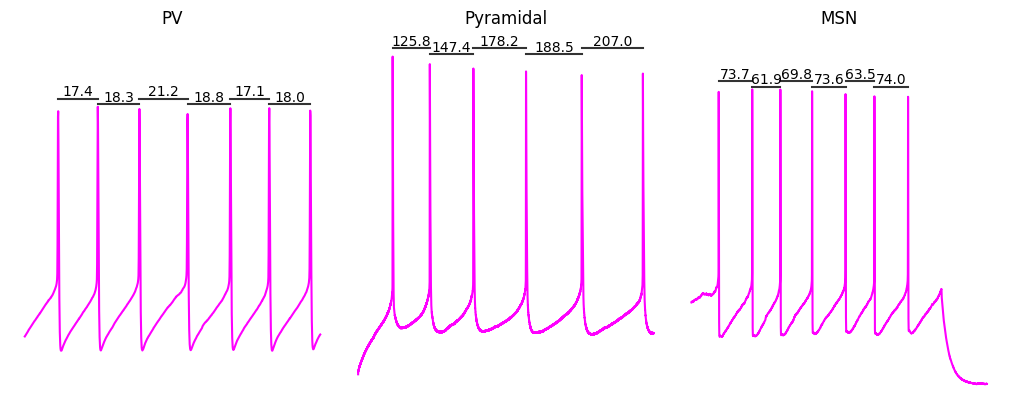

In [175]:
def plot_isi_width(array, ax):
    peaks, _ = signal.find_peaks(array, height=10)
    top = np.max(array[peaks])
    for i in range(len(peaks) - 1):
        t = (peaks[i + 1] - peaks[i]) / 10
        ax.plot(
            [peaks[i], peaks[i + 1]],
            [top + (i + 1) % 2 * 2 + 1, top + (i + 1) % 2 * 2 + 1],
            color="black",
            alpha=0.8,
        )
        ax.annotate(
            t,
            xy=(
                peaks[i] + ((peaks[i + 1] - peaks[i]) / 2),
                top + (i + 1) % 2 * 2 + 1,
            ),  # Target location in data coordinates
            xycoords="data",
            xytext=(0.0, 0.0),  # Offset: 8 points left, 0 points vertical
            textcoords="offset points",
            ha="center",  # Align right edge of text to the offset point
            va="bottom",
            fontsize=10,
        )


fig, ax = plt.subplots(ncols=3, layout="constrained", sharey=True, figsize=(10, 4))
ax[0].plot(pv[6000:7300], color="magenta")
ax[0].set_title("PV")
plot_isi_width(pv[6000:7300], ax[0])
ax[1].plot(pyr_adapt[5000:15000], color="magenta")
ax[1].set_title("Pyramidal")
plot_isi_width(pyr_adapt[5000:15000], ax[1])
ax[2].plot(msn[4500:11000], color="magenta")
ax[2].set_title("MSN")
plot_isi_width(msn[4500:11000], ax[2])
for i in ax:
    i.set_axis_off()

## Spike repolarization

Spike repolorization occurs once the spike has the peak spike voltage. If we pick a single spike from a PV interneuron and pyramidal neuron we can see that the minimum voltage after the spike is much larger in the PV interneuron. Spike repolarization is driven by BK channels; large current Ca++ and voltaged-gated potassium channels. Cortical interneurons express a BK channel subunit, KCNMB2, that increases the calcium and voltage sensitivity of the channels and decreases the time it spends open with an intracellular gating mechanism [@liModulationBKChannel2016; @contetBKChannelsCentral2016]. So the BK channels turn on sooner, truncating the the action potential and turn off quickly shortening the fAHP. However, Kv3 channels also play a role. They are only activated at higher voltages (close to 0 mV) and have fast activation and deactivation kinetics. They are highly expressed by PV interneurons and another important factor in allow PV neurons to have a short spike and deep AHP.

In [176]:
signal.find_peaks(msn, height=10)

(array([5100, 5837, 6456, 7154, 7890, 8525, 9265]),
 {'peak_heights': array([34.73744462, 35.65828308, 35.59250891, 34.96765423, 33.91526741,
         33.0930902 , 32.92865476])})

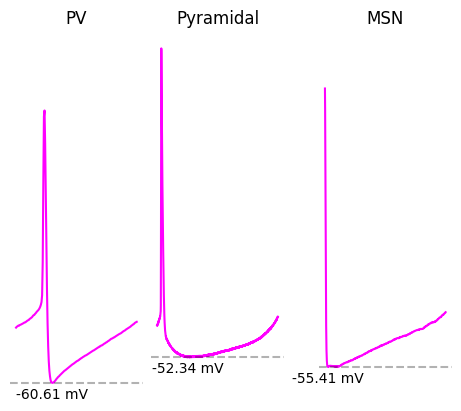

In [179]:
def plot_repol(array, ax):
    ax.plot(array, color="magenta")
    val = round(array.min(), 2)
    val_index = array.argmin()
    ax.axhline(val, color="black", alpha=0.3, linestyle="dashed")
    ax.annotate(
        f"{val} mV",
        xy=(val_index, val),  # Target location in data coordinates
        xycoords="data",
        xytext=(0.0, -3),  # Offset: 8 points left, 0 points vertical
        textcoords="offset points",
        ha="center",  # Align right edge of text to the offset point
        va="top",
        fontsize=10,
    )


fig, ax = plt.subplots(ncols=3, layout="constrained", sharey=True, figsize=(4.5, 4))
plot_repol(pv[6100:6300], ax[0])
ax[0].set_title("PV")
plot_repol(pyr_adapt[6125:7400], ax[1])
ax[1].set_title("Pyramidal")
plot_repol(msn[5100:5800], ax[2])
ax[2].set_title("MSN")
for i in ax:
    i.set_axis_off()

## Spike doublets and burst firing in pyramidal neurons
Pyramidal neurons can firing short, high frequency bursts when stimulated with a large current injection. At lower current injections they also have doublet or triplet or short ISI spikes. These are due to back propogating action potentials (BAPs), denritic calcium and the dendritic structure itself. When a pyramidal neuron initiates an action potential at the soma/axon hillock, the Na+ wave can travel back into the dendrites causing T-type Ca++ channels to open which then travel back to the soma eliciting another spike earlier than expected. Additionally, if you inject a depolarizing current into the dendrite you induce a doublet even at low currents. The dendritic Ca++ currents can get large enough to elicit a spike indepedent of Na+. While cell types have some Ca++ increase in the dendrites not all cells have BAPs. Some neurons, like PV interneurons, have no somatic action potential induced dendritic Ca++[@huFastspikingParvalbuminGABAergic2014].

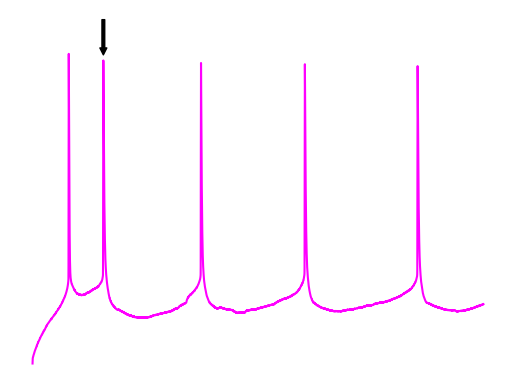

In [158]:
fig, ax = plt.subplots()
ax.plot(pyr_doublet[3000:10000], color="magenta")
ax.annotate(
    "",
    xy=(1099, 40),
    xytext=(1099, 55),
    arrowprops={"arrowstyle": "simple", "facecolor": "black"},
)
_ = ax.set_ylim((None, 55 * 0.05 + 55))
ax.set_axis_off()